# WildfireSpreadTS × STConvS2S — integração

Resultados dos runs de `scripts/stconv_train.py`. **Protocolo:** fold fixado antes de qualquer treino;
checkpoint escolhido pela maior AP de validação; threshold pelo maior F2 de validação; o ano de teste é
avaliado **uma única vez por run pré-registrado**, a partir do checkpoint com SHA conferido, e cada
avaliação fica registrada em `reports/test_ledger.jsonl`.

O pré-registro (configuração, seeds, métricas e regra de decisão dos ablations) foi fixado antes do
primeiro run completo; os parâmetros que decidem a leitura estão em `scripts/core.py`
(`PREREGISTERED_*`, `ABLATION_*`).

In [1]:
import json
from pathlib import Path

import pandas as pd
from IPython.display import Markdown, display

def find_root():
    for candidate in (Path.cwd(), *Path.cwd().parents):
        reports = candidate / 'reports'
        if (reports / 'stconv_runs').is_dir() or (reports / 'demo_runs').is_dir():
            return candidate
    raise FileNotFoundError('Rode scripts/stconv_train.py antes de abrir este notebook.')

ROOT = find_root()
RUNS_DIR = ROOT / 'reports' / 'stconv_runs'
DEMO_DIR = ROOT / 'reports' / 'demo_runs'
runs, kind = {}, 'full'
if RUNS_DIR.is_dir():
    for path in sorted(RUNS_DIR.glob('*.json')):
        report = json.loads(path.read_text(encoding='utf-8'))
        if report.get('kind') == 'full':
            runs[report['run_name']] = report
if not runs and DEMO_DIR.is_dir():
    kind = 'demo'
    for path in sorted(DEMO_DIR.glob('*.json')):
        report = json.loads(path.read_text(encoding='utf-8'))
        if report.get('kind') == 'demo':
            runs[report['run_name']] = report
if not runs:
    raise FileNotFoundError(f'Nenhum run em {RUNS_DIR} nem em {DEMO_DIR}.')
if kind == 'demo':
    display(Markdown(
        '> ⚠️ **Demonstração, não evidência.** Estes runs usaram uma amostra de '
        f"{next(iter(runs.values()))['config']['max_events']} eventos por ano e o conjunto de teste "
        'não foi avaliado. Servem para mostrar que o fluxo roda ponta a ponta; '
        'nenhum número aqui sustenta conclusão sobre desempenho.'
    ))

def label(report):
    dropped = report['protocol']['drop_groups']
    base = 'completo' if not dropped else 'sem ' + '+'.join(dropped)
    return f"{base} (seed {report['config']['seed']})"

reference = next(iter(runs.values()))
display(Markdown(
    f"**{len(runs)} run(s) ({kind})** · fold {reference['protocol']['fold']} · "
    f"T_in = {reference['protocol']['t_in']} · alvo: {reference['protocol']['target']}"
))
display(pd.DataFrame([{
    'run': name, 'configuração': label(r), 'épocas': len(r['history']),
    'melhor época': r['best_epoch'], 'teste avaliado': 'test' in r,
         'tipo': r['kind'],
    'commit': (r['provenance']['repo']['commit'] or '?')[:7],
} for name, r in runs.items()]).set_index('run'))

> ⚠️ **Demonstração, não evidência.** Estes runs usaram uma amostra de 10 eventos por ano e o conjunto de teste não foi avaliado. Servem para mostrar que o fluxo roda ponta a ponta; nenhum número aqui sustenta conclusão sobre desempenho.

**9 run(s) (demo)** · fold 2 · T_in = 5 · alvo: fogo ativo binário em t+1

,configuração,épocas,melhor época,teste avaliado,tipo,commit
run,,,,,,
principal_s42,completo (seed 42),5,1,False,demo,45c1c9c
principal_s43,completo (seed 43),5,1,False,demo,45c1c9c
principal_s44,completo (seed 44),5,5,False,demo,45c1c9c
sem_gfs_s42,sem gfs (seed 42),5,5,False,demo,45c1c9c
sem_gfs_s43,sem gfs (seed 43),5,1,False,demo,45c1c9c
sem_gfs_s44,sem gfs (seed 44),5,5,False,demo,45c1c9c
sem_veg_s42,sem vegetation_index (seed 42),5,4,False,demo,45c1c9c
sem_veg_s43,sem vegetation_index (seed 43),5,1,False,demo,45c1c9c
sem_veg_s44,sem vegetation_index (seed 44),5,5,False,demo,45c1c9c


## 1. Contrato de dados

Cada amostra é uma janela de `T_in` dias consecutivos de um mesmo evento. O alvo é a máscara binária de fogo
ativo do dia seguinte. A máscara `M` vale 1 em todo pixel avaliado — **inclusive os negativos** — e 0 apenas
em padding e no halo dos tiles, de modo que a classe majoritária continua entrando na loss e nas métricas.

In [2]:
protocol = reference['protocol']
display(pd.Series({
    'fold': protocol['fold'],
    'treino': protocol['split']['train'],
    'validação': protocol['split']['validation'],
    'teste': protocol['split']['test'],
    'dias de entrada (T_in)': protocol['t_in'],
    'leitura da saída': protocol['readout'],
    'amostragem de treino': protocol['train_sampling'],
    'tiles na avaliação': protocol['eval_tiling'],
    'nº de canais': len(protocol['channels']),
}).to_frame('contrato'))
display(Markdown('**Vistas avaliadas**'))
display(pd.Series(protocol['views']).to_frame('definição'))
display(Markdown('**Baselines de persistência**'))
display(pd.Series(protocol['baselines']).to_frame('campo usado como predição'))
print(protocol['baseline_notes'])
print()
print('Canais:', ', '.join(protocol['channels']))

,contrato
fold,2
treino,"[2018, 2020]"
validação,[2019]
teste,[2021]
dias de entrada (T_in),5
leitura da saída,"logits[:, :, -1:] (convenção de leitura)"
amostragem de treino,"1 recorte/janela/época, regra oficial de 10 so..."
tiles na avaliação,tiles 128 px com halo 8 px (raio receptivo 4);...
nº de canais,47


**Vistas avaliadas**

,definição
all,todos os pixels
crop32,center_crop_x32 (comparável ao artigo)
new_vs_t,pixels sem fogo em t
new_vs_window,pixels sem fogo em t−T_in+1..t


**Baselines de persistência**

,campo usado como predição
persistence_all_detections_t,fire_t
persistence_last_pass_t,fire_last_t
persistence_window_union,fire_window


persistência 'última passagem' usa a hora máxima de t na imagem inteira (oficial: no tensor já recortado); difere só na vista crop32 quando o pixel de hora máxima cai fora do recorte

Canais: viirs_m11, viirs_i2, viirs_i1, ndvi, evi2, precipitation, wind_speed, temperature_min, temperature_max, energy_release_component, specific_humidity, slope, elevation, pdsi, forecast_wind_speed, forecast_temperature, forecast_specific_humidity, wind_direction_sin, wind_direction_cos, aspect_sin, aspect_cos, forecast_wind_direction_sin2, forecast_wind_direction_cos2, landcover_evergreen_needleleaf_forests, landcover_evergreen_broadleaf_forests, landcover_deciduous_needleleaf_forests, landcover_deciduous_broadleaf_forests, landcover_mixed_forests, landcover_closed_shrublands, landcover_open_shrublands, landcover_woody_savannas, landcover_savannas, landcover_grasslands, landcover_permanent_wetlands, landcover_croplands, landcover_urban_and_built_up_lands, landcover_cropland_natural_vegetation_mosaics,

## 2. Treino e seleção

`pos_weight` é estimado sob a mesma distribuição de recortes usada no treino. O checkpoint guardado é o da
época com maior AP de validação; nenhuma métrica de teste participa da seleção.

### principal_s42 — completo (seed 42)

`pos_weight` = **1955.0** (2203 positivos / 4306789 negativos em 263 recortes) · janelas: 263 treino, 157 validação · pico de VRAM: 1786.9 MiB

,epoch_seconds,train_loss,train_seconds,val_ap,val_ap_new_vs_t
epoch,,,,,
1,57.7,1.43426,23.8,0.00147,0.00137
2,53.9,1.22135,22.3,0.00072,0.00059
3,55.1,1.06033,22.4,0.00083,0.00066
4,54.0,0.92100,22.4,0.00072,0.00057
5,53.3,0.97884,21.5,0.00090,0.00062


### principal_s43 — completo (seed 43)

`pos_weight` = **1961.2** (2196 positivos / 4306796 negativos em 263 recortes) · janelas: 263 treino, 157 validação · pico de VRAM: 1786.9 MiB

...

`pos_weight` = **1961.2** (2196 positivos / 4306796 negativos em 263 recortes) · janelas: 263 treino, 157 validação · pico de VRAM: 1784.2 MiB

,epoch_seconds,train_loss,train_seconds,val_ap,val_ap_new_vs_t
epoch,,,,,
1,53.7,1.52016,22.9,0.00087,0.00070
2,52.0,1.27423,21.5,0.00075,0.00055
3,52.6,1.06696,22.0,0.00082,0.00062
4,51.7,1.05731,21.6,0.00076,0.00057
5,52.6,0.91343,22.3,0.00087,0.00068


### sem_veg_s44 — sem vegetation_index (seed 44)

`pos_weight` = **1993.9** (2160 positivos / 4306832 negativos em 263 recortes) · janelas: 263 treino, 157 validação · pico de VRAM: 1784.2 MiB

,epoch_seconds,train_loss,train_seconds,val_ap,val_ap_new_vs_t
epoch,,,,,
1,52.7,1.48074,22.0,0.00103,0.00067
2,51.5,1.17501,21.7,0.00094,0.00066
3,52.4,1.12352,22.1,0.00077,0.00061
4,52.6,1.01194,22.2,0.00086,0.00069
5,52.2,0.87863,21.4,0.00124,0.00095


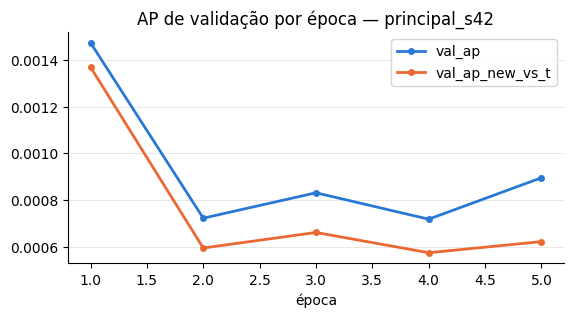

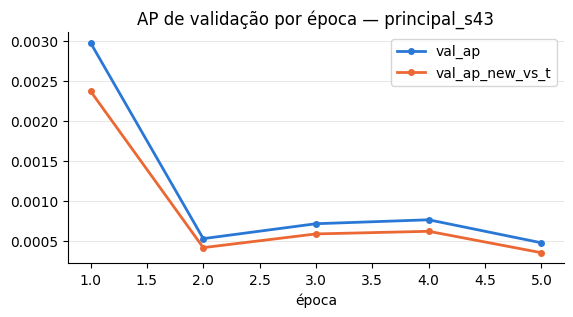

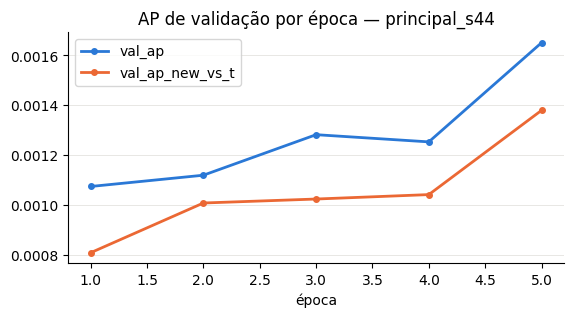

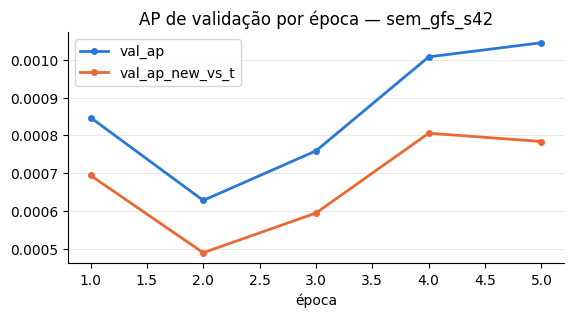

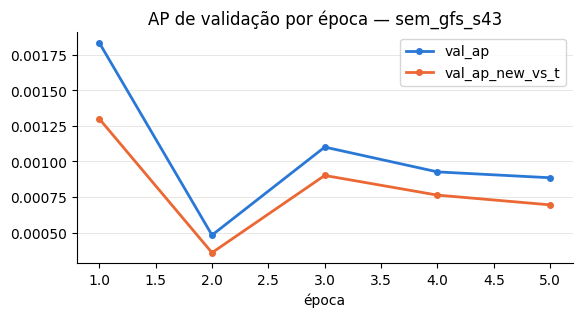

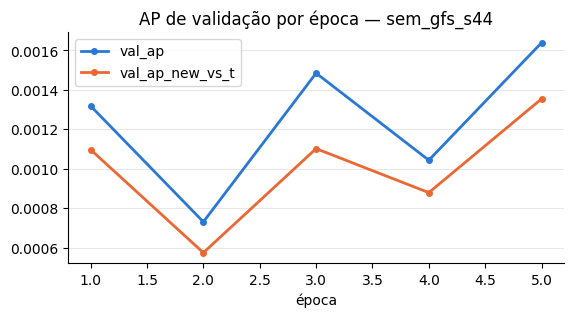

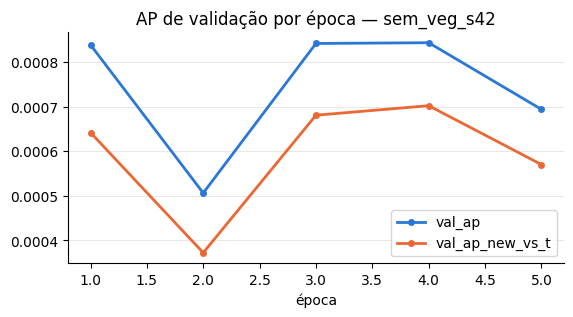

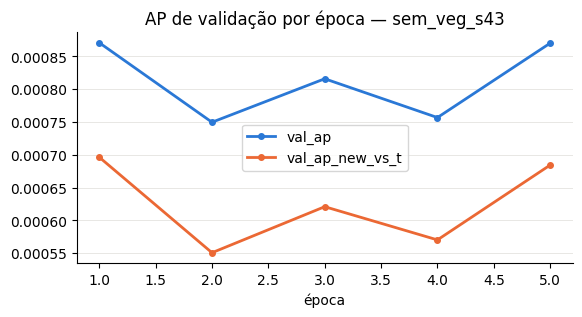

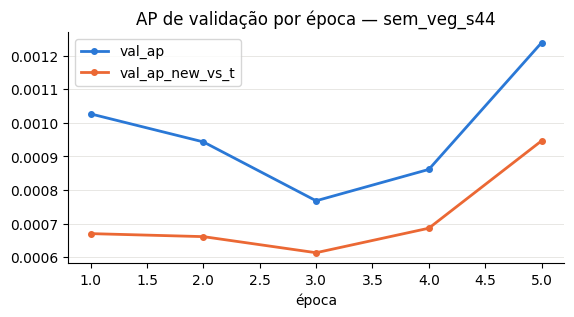

In [3]:
for name, report in runs.items():
    display(Markdown(f"### {name} — {label(report)}"))
    pw = report['pos_weight']
    display(Markdown(
        f"`pos_weight` = **{pw['pos_weight']:.1f}** ({pw['positive']} positivos / {pw['negative']} negativos "
        f"em {pw['samples']} recortes) · janelas: {report['n_train_windows']} treino, "
        f"{report['n_validation_windows']} validação · pico de VRAM: {report['peak_vram_mib']} MiB"
    ))
    history = pd.DataFrame(report['history']).set_index('epoch')
    display(history.round(5))
    if len(history) > 1:
        ax = history[['val_ap', 'val_ap_new_vs_t']].plot(
            figsize=(6.4, 3), marker='o', markersize=4, linewidth=2,
            color=['#2a78d6', '#eb6834'], title=f'AP de validação por época — {name}')
        ax.set_xlabel('época'); ax.grid(axis='y', color='#e4e3df', linewidth=0.6); ax.set_axisbelow(True)
        for side in ('top', 'right'):
            ax.spines[side].set_visible(False)

## 3. Métricas por vista

A métrica primária é a AP (*average precision*), adequada a classe rara. O IC 95% vem de bootstrap
reamostrando **eventos inteiros**, não pixels: pixels do mesmo incêndio são fortemente dependentes.

- `all` — todos os pixels avaliados
- `crop32` — recorte central múltiplo de 32, vista comparável à do artigo
- `new_vs_t` — só pixels sem fogo em t (onde a persistência não ajuda)
- `new_vs_window` — só pixels sem fogo em nenhum dos dias de entrada

In [4]:
def metric_rows(block, origin, run):
    rows = []
    for view, entry in block.items():
        model, ci = entry['model'], entry.get('ap_bootstrap_events')
        at = entry.get('model_at_validation_threshold', {})
        rows.append({
            'run': run, 'origem': origin, 'vista': view,
            'AP': model['average_precision'],
            'IC 95% AP': None if not ci else f"[{ci['ci95'][0]:.4f}; {ci['ci95'][1]:.4f}]",
            'AP prevalência': entry['prevalence_baseline_ap'],
            'F2': at.get('f2'), 'precisão': at.get('precision'), 'recall': at.get('recall'),
            'positivos': model['n_positive'],
        })
    return rows

rows = []
for name, report in runs.items():
    rows += metric_rows(report['validation'], 'validação', name)
    if 'test' in report:
        rows += metric_rows(report['test']['metrics'], 'teste', name)
display(pd.DataFrame(rows).set_index(['run', 'origem', 'vista']).round(5))

AP         IC 95% AP  \
run           origem    vista                                      
principal_s42 validação all            0.00147  [0.0004; 0.0026]   
                        crop32         0.00153  [0.0004; 0.0027]   
                        new_vs_t       0.00137  [0.0002; 0.0025]   
                        new_vs_window  0.00135  [0.0002; 0.0024]   
principal_s43 validação all            0.00297  [0.0003; 0.0046]   
                        crop32         0.00300  [0.0003; 0.0047]   
                        new_vs_t       0.00237  [0.0002; 0.0035]   
                        new_vs_window  0.00229  [0.0002; 0.0033]   
principal_s44 validação all            0.00165  [0.0004; 0.0025]   
                        crop32         0.00169  [0.0004; 0.0024]   
                        new_vs_t       0.00138  [0.0002; 0.0024]   
                        new_vs_window  0.00128  [0.0002; 0.0023]   
sem_gfs_s42   validação all            0.00105  [0.0003; 0.0028]   
                        crop32         0.00113  [0.0004; 0.0028]   
                        new_vs_t       0.00078  [0.0002; 0.0021]   
                        new_vs_window  0.00072  [0.0002; 0.0019]   
sem_gfs_s43   validação all            0.00184  [0.0004; 0.0031]   
                        crop32         0.00200  [0.0004; 0.0032]   
                        new_vs_t       0.00130  [0.0003; 0.0023]   
                        new_vs_window  0.00123  [0.0002; 0.0022]   
sem_gfs_s44   validação all            0.00164  [0.0003; 0.0031]   
                        crop32         0.00173  [0.0003; 0.0033]   
                        new_vs_t       0.00135  [0.0002; 0.0026]   
                        new_vs_window  0.00134  [0.0002; 0.0026]   
sem_veg_s42   validação all            0.00084  [0.0002; 0.0016]   
                        crop32         0.00089  [0.0003; 0.0017]   
                        new_vs_t       0.00070  [0.0002; 0.0014]   
                        new_vs_window  0.00067  [0.0002; 0.0013]   
sem_veg_s43   validação all            0.00087  [0.0003; 0.0012]   
                        crop32         0.00092  [0.0003; 0.0013]   
                        new_vs_t       0.00070  [0.0002; 0.0010]   
                        new_vs_window  0.00066  [0.0002; 0.0009]   
sem_veg_s44   validação all            0.00124  [0.0004; 0.0020]   
                        crop32         0.00130  [0.0004; 0.0020]   
                        new_vs_t       0.00095  [0.0002; 0.0016]   
                        new_vs_window  0.00086  [0.0002; 0.0015]   

                                       AP prevalência       F2  precisão  \
run           origem    vista                                              
principal_s42 validação all                   0.00070  0.01399   0.00360   
                        crop32                0.00078  0.01257   0.00330   
                        new_vs_t              0.00052  0.01482   0.00358   
                        new_vs_window         0.00048  0.01502   0.00358   
principal_s43 validação all                   0.00070  0.02835   0.00703   
                        crop32                0.00078  0.02845   0.00706   
                        new_vs_t              0.00052  0.02327   0.00548   
                        new_vs_window         0.00048  0.02216   0.00517   
principal_s44 validação all                   0.00070  0.01379   0.00290   
                        crop32                0.00078  0.01397   0.00295   
                        new_vs_t              0.00052  0.01163   0.00241   
                        new_vs_window         0.00048  0.01093   0.00226   
sem_gfs_s42   validação all                   0.00070  0.00622   0.00126   
                        crop32                0.00078  0.00679   0.00138   
                        new_vs_t              0.00052  0.00478   0.00097   
                        new_vs_window         0.00048  0.00445   0.00090   
sem_gfs_s43   validação all                   0.00070  0.01403   0.00292   
               

## 4. Comparação com persistência

O baseline a bater é a persistência: repetir o mapa de fogo do dia anterior. O IC pareado reamostra os
mesmos eventos para o modelo e para a persistência, então mede a diferença dentro de cada evento.

In [5]:
rows = []
for name, report in runs.items():
    for origin, block in [('validação', report['validation'])] + (
            [('teste', report['test']['metrics'])] if 'test' in report else []):
        entry = block['all']
        for baseline, metrics in entry['baselines'].items():
            rows.append({'run': name, 'origem': origin, 'baseline': baseline,
                         'F2': metrics['f2'], 'precisão': metrics['precision'], 'recall': metrics['recall']})
        at = entry.get('model_at_validation_threshold', {})
        rows.append({'run': name, 'origem': origin, 'baseline': '** modelo **',
                     'F2': at.get('f2'), 'precisão': at.get('precision'), 'recall': at.get('recall')})
display(pd.DataFrame(rows).set_index(['run', 'origem', 'baseline']).round(5))

display(Markdown('**Teste pareado: F2(modelo) − F2(persistência de todas as detecções de t)**'))
paired = []
for name, report in runs.items():
    for origin, block in [('validação', report['validation'])] + (
            [('teste', report['test']['metrics'])] if 'test' in report else []):
        p = block['all'].get('f2_vs_persistence_paired_bootstrap')
        if p:
            paired.append({'run': name, 'origem': origin, 'diferença': p['point'],
                           'IC 95%': f"[{p['ci95'][0]:.4f}; {p['ci95'][1]:.4f}]",
                           'supera persistência': p['model_beats_persistence'], 'eventos': p['n_events']})
display(pd.DataFrame(paired).set_index(['run', 'origem']).round(5) if paired
        else Markdown('_IC pareado indisponível (menos de 3 eventos)._'))

F2  precisão  \
run           origem    baseline                                          
principal_s42 validação persistence_all_detections_t  0.26902   0.27271   
                        persistence_last_pass_t       0.20526   0.35092   
                        persistence_window_union      0.21503   0.09114   
                        ** modelo **                  0.01399   0.00360   
principal_s43 validação persistence_all_detections_t  0.26902   0.27271   
                        persistence_last_pass_t       0.20526   0.35092   
                        persistence_window_union      0.21503   0.09114   
                        ** modelo **                  0.02835   0.00703   
principal_s44 validação persistence_all_detections_t  0.26902   0.27271   
                        persistence_last_pass_t       0.20526   0.35092   
                        persistence_window_union      0.21503   0.09114   
                        ** modelo **                  0.01379   0.00290   
sem_gfs_s42   validação persistence_all_detections_t  0.26902   0.27271   
                        persistence_last_pass_t       0.20526   0.35092   
                        persistence_window_union      0.21503   0.09114   
                        ** modelo **                  0.00622   0.00126   
sem_gfs_s43   validação persistence_all_detections_t  0.26902   0.27271   
                        persistence_last_pass_t       0.20526   0.35092   
                        persistence_window_union      0.21503   0.09114   
                        ** modelo **                  0.01403   0.00292   
sem_gfs_s44   validação persistence_all_detections_t  0.26902   0.27271   
                        persistence_last_pass_t       0.20526   0.35092   
                        persistence_window_union      0.21503   0.09114   
                        ** modelo **                  0.01426   0.00314   
sem_veg_s42   validação persistence_all_detections_t  0.26902   0.27271   
                        persistence_last_pass_t       0.20526   0.35092   
                        persistence_window_union      0.21503   0.09114   
                        ** modelo **                  0.00557   0.00115   
sem_veg_s43   validação persistence_all_detections_t  0.26902   0.27271   
                        persistence_last_pass_t       0.20526   0.35092   
                        persistence_window_union      0.21503   0.09114   
                        ** modelo **                  0.00515   0.00104   
sem_veg_s44   validação persistence_all_detections_t  0.26902   0.27271   
                        persistence_last_pass_t       0.20526   0.35092   
                        persistence_window_union      0.21503   0.09114   
                        ** modelo **                  0.00803   0.00167   

                                                       recall  
run           origem    baseline                               
principal_s42 validação persistence_all_detections_t  0.26811  
                        persistence_last_pass_t       0.18596  
                        persistence_window_union      0.32572  
                        ** modelo **                  0.05036  
principal_s43 validação persistence_all_detections_t  0.26811  
                        persistence_last_pass_t       0.18596  
                        persistence_window_union      0.32572  
                        ** modelo **                  0.11725  
principal_s44 validação persistence_all_detections_t  0.26811  
                        persistence_last_pass_t       0.18596  
                        persistence_window_union      0.32572  
                        ** modelo **                  0.22928  
sem_gfs_s42   validação persistence_all_detections_t  0.26811  
                        persistence_last_pass_t       0.18596  
                        persistence_window_union      0.32572  
                        ** modelo **                  0.37288  
sem_gfs_s43   validação persistence_all_detections_t  0.

**Teste pareado: F2(modelo) − F2(persistência de todas as detecções de t)**

,,diferença,IC 95%,supera persistência,eventos
run,origem,,,,
principal_s42,validação,-0.25547,[-0.3847; -0.1419],False,10
principal_s43,validação,-0.24079,[-0.3832; -0.1381],False,10
principal_s44,validação,-0.25522,[-0.3839; -0.1448],False,10
sem_gfs_s42,validação,-0.26281,[-0.3824; -0.1533],False,10
sem_gfs_s43,validação,-0.25506,[-0.3757; -0.1536],False,10
sem_gfs_s44,validação,-0.25476,[-0.3846; -0.1527],False,10
sem_veg_s42,validação,-0.26346,[-0.3840; -0.1547],False,10
sem_veg_s43,validação,-0.26387,[-0.3806; -0.1611],False,10
sem_veg_s44,validação,-0.26099,[-0.3838; -0.1536],False,10


## 5. Ablations

Dois grupos de canais são removidos em runs separados, conforme o pré-registro:

- **sem NDVI/EVI2** — esses canais vêm de um composto de 16 dias que pode conter observações posteriores ao
  dia alvo (*look-ahead* estrutural). Uma queda grande é ambígua, porque mistura sinal legítimo com
  vazamento; uma queda desprezível indica que o look-ahead não é relevante para o modelo.
- **sem canais GFS** — a previsão meteorológica tem horizonte efetivo provavelmente longo (vários dias),
  então seu papel preditivo precisa ser medido, não assumido.

In [6]:
import itertools
import numpy as np

by_config = {}
for report in runs.values():
    by_config.setdefault(tuple(report['protocol']['drop_groups']), []).append(report)

summary = []
for dropped, group in by_config.items():
    aps = [r['validation']['all']['model']['average_precision'] for r in group]
    summary.append({'configuração': 'completo' if not dropped else 'sem ' + '+'.join(dropped),
                    'seeds': len(aps), 'AP média (validação)': np.mean(aps),
                    'desvio entre seeds': np.std(aps, ddof=1) if len(aps) > 1 else np.nan})
display(pd.DataFrame(summary).set_index('configuração').round(5))

baseline_key = ()
if baseline_key in by_config and len(by_config) > 1:
    base = [r['validation']['all']['model']['average_precision'] for r in by_config[baseline_key]]
    rows = []
    for dropped, group in by_config.items():
        if dropped == baseline_key:
            continue
        aps = [r['validation']['all']['model']['average_precision'] for r in group]
        pooled = np.sqrt((np.var(base, ddof=1) + np.var(aps, ddof=1)) / 2) if min(len(base), len(aps)) > 1 else np.nan
        effect = np.mean(base) - np.mean(aps)
        rows.append({'ablation': 'sem ' + '+'.join(dropped), 'efeito (ΔAP)': effect,
                     'desvio agrupado': pooled,
                     'relevante': bool(abs(effect) > 2 * pooled and abs(effect) > 0.01) if pooled == pooled else None})
    display(pd.DataFrame(rows).set_index('ablation').round(5))
    display(Markdown(
        '_Regra pré-registrada: o efeito é relevante se |ΔAP| > 2 × desvio agrupado **e** > 0,01 **e** o IC '
        'pareado por eventos exclui 0._'))
else:
    display(Markdown('_Ablations ainda não executados._'))

,seeds,AP média (validação),desvio entre seeds
configuração,,,
completo,3,0.00203,0.00082
sem gfs,3,0.00151,0.00041
sem vegetation_index,3,0.00098,0.00022


,efeito (ΔAP),desvio agrupado,relevante
ablation,,,
sem gfs,0.00053,0.00065,False
sem vegetation_index,0.00105,0.00060,False


_Regra pré-registrada: o efeito é relevante se |ΔAP| > 2 × desvio agrupado **e** > 0,01 **e** o IC pareado por eventos exclui 0._

## 6. Proveniência e protocolo de teste

Cada relatório registra o commit do código, o SHA-256 dos scripts executados, o commit do clone do
STConvS2S, a versão do PyTorch/CUDA e o SHA-256 do arquivo de normalização e do checkpoint avaliado. O
livro-razão abaixo lista toda avaliação de teste já realizada — por construção, ele só cresce.

In [7]:
rows = []
for name, report in runs.items():
    prov = report['provenance']
    rows.append({
        'run': name,
        'commit': (prov['repo']['commit'] or '?')[:7],
        'árvore suja': prov['repo']['dirty'],
        'stconvs2s': (prov['stconvs2s'] or {}).get('commit', '?')[:7],
        'torch': prov['torch']['version'],
        'checkpoint sha256': report['checkpoint_sha256'][:12],
    })
display(pd.DataFrame(rows).set_index('run'))
display(Markdown('**Determinismo**'))
display(pd.Series(reference['protocol']['determinism']).to_frame('configuração'))

ledger = ROOT / 'reports' / 'test_ledger.jsonl'
if ledger.exists():
    entries = [json.loads(line) for line in ledger.read_text(encoding='utf-8').splitlines() if line.strip()]
    display(Markdown(f'**Livro-razão de avaliações do teste** ({len(entries)} registro(s))'))
    display(pd.DataFrame(entries))
else:
    display(Markdown('_Nenhuma avaliação de teste registrada._'))

,commit,árvore suja,stconvs2s,torch,checkpoint sha256
run,,,,,
principal_s42,45c1c9c,False,c355e9e,2.13.0+cu126,48ae989b871f
principal_s43,45c1c9c,False,c355e9e,2.13.0+cu126,ab73c6814601
principal_s44,45c1c9c,False,c355e9e,2.13.0+cu126,265f934760cd
sem_gfs_s42,45c1c9c,False,c355e9e,2.13.0+cu126,a42aa0351677
sem_gfs_s43,45c1c9c,False,c355e9e,2.13.0+cu126,e8c258441b05
sem_gfs_s44,45c1c9c,False,c355e9e,2.13.0+cu126,36d270a6ea63
sem_veg_s42,45c1c9c,False,c355e9e,2.13.0+cu126,e1a73f592aba
sem_veg_s43,45c1c9c,False,c355e9e,2.13.0+cu126,67d3737555a0
sem_veg_s44,45c1c9c,False,c355e9e,2.13.0+cu126,365c129dee80


**Determinismo**

,configuração
cublas_workspace_config,:4096:8
cudnn_benchmark,False
cudnn_deterministic,True
note,conv3d em CUDA pode não ter kernel determiníst...
seed,42
use_deterministic_algorithms,warn_only


_Nenhuma avaliação de teste registrada._

## 7. Limitações

- **Fold único.** O artigo original agrega 12 folds; aqui há um só, então não há estimativa de variância
  entre folds e os números não são diretamente comparáveis às tabelas do artigo.
- **Ruído de rótulo.** Pixels marcados como negativos incluem fogo que o VIIRS não detectou (nuvem, omissão),
  então a classe negativa está contaminada.
- **Fogo ativo ≠ perímetro.** O alvo é detecção de fogo ativo no dia, não a área queimada acumulada.
- **`pos_weight` diferente do oficial**, calculado sob a distribuição de recortes em vez de 1/taxa global.
- **Ângulos no norte verdadeiro.** As convoluções operam na grade UTM, que está rotacionada em relação ao
  norte verdadeiro em até ~14° nos eventos mais a leste.
- **Sem augmentation geométrica**, que exigiria transformar também os ângulos e vetores.